# Real-Time Fraud Detection — Fine-Tuned Hinglish Transformer (ICFD-31k) · Run 5 (final: ensemble chosen on validation)
**Hemanth M (`1AT24CS074`) · Review 2 · Supervised model track · runs on Kaggle GPU T4 × 2**

### Why this notebook exists
All four unsupervised detectors (Isolation Forest, Mahalanobis, One-Class SVM, Deep Autoencoder) scored ROC-AUC ≈ 0.51 on the shared PCA-40 features. A diagnosis showed the fraud signal *is* in the data, but it is a **"has the scam request happened yet?"** signal (OTP / PIN / card-number requests, threats, urgency) that a model only learns **with labels**. The ICFD-31k authors (Ahuja, Prateek & Singh, IJCAI 2026) reached 95.6 % streaming F1 by **fine-tuning RoBERTa on per-chunk labels**. This notebook follows that recipe, adapted for Hinglish and for our course rules.

### Design (research-backed)
| Decision | Choice | Reason |
|---|---|---|
| Backbone | Bake-off: `FacebookAI/xlm-roberta-base`, `l3cube-pune/hing-roberta`, `google/muril-base-cased` → keep the best on validation | HingRoBERTa (XLM-R further pre-trained on Roman-script Hinglish) leads code-mixed benchmarks; MuRIL is the main Indian-language alternative; XLM-R is the multilingual default |
| Input | `cumulative_text` with speaker tags (`Agent: … Customer: …`) — the only text field | Same input as the paper's streaming model (M2) |
| Long calls (> 512 tokens) | **Head + tail truncation**: first 128 + last 382 tokens | Keeps who-is-calling + the most recent turns (where the scam ask appears); best strategy in Sun et al. 2019 |
| Labels | Per-chunk verdict (`final_verdict` of each 3-second chunk: NO before the scam ask, YES after) | Same as the paper's M2 |
| Training | **Run 2:** lr 1e-5, label smoothing 0.1, 1 epoch, validation every 500 steps, early stopping on validation ROC-AUC (patience 6); effective batch 16, warm-up 6 %, weight-decay 0.01, fp16 | Run 1 used the paper's lr 2e-5: validation ROC-AUC oscillated (0.90 → 0.76 → 0.85 → 0.75) and the best checkpoint came at only 10 % of epoch 1 — a too-high learning rate / over-confidence pattern, so run 2 lowers lr, adds label smoothing and checks validation 4× more often |
| 2 GPUs | **PyTorch DDP via `torchrun`** (one process per T4) | Reliable multi-GPU on Kaggle; in-process DataParallel/notebook launchers often fall back to 1 GPU |
| ≤ 50-feature rule | Fine-tuned 768-d text features + audio/time features (> 50) → `StandardScaler` → **PCA (≤ 50 comps, chosen on validation)** → Logistic Regression | Teacher's rule: if features > 50, apply PCA. The PCA model is the **official** model; the raw transformer head is reported only as a reference |
| Leakage | Only `cumulative_text`, `cumulative_audio_analysis_json`, `chunk_timestamp` are inputs. `slow_thinking_rationale`, `case_type`, `scenario_*`, `domain`, `final_verdict` are **never** model inputs | Annotation fields would reveal the answer |
| Splits | Official HF train / validation / test. Train calls split by `conversation_uid` into fine-tune / *head* (10 %, PCA + classifier fit) / **held-out legitimate calls (15 % of legit train calls) added to validation & test** | Official val/test contain only 49 legitimate calls each, too few to measure false alarms; the classifier must be fitted on chunks the transformer has not memorised |
| Unseen scam types | Official **cross-domain** split (1,000 calls: crypto, romance, investment, charity, tax; 442 legitimate) used only for final testing | Generalisation to scam types never seen in training (paper reports a 6-point F1 drop here) |
| ASR robustness | 30 % of training texts get speech-to-text-style noise (dropped words, typos, Hinglish spelling variants, no punctuation/case); a noisy copy of the test set measures robustness | Noise injection is the standard fix for ASR error propagation in spoken-language classifiers |
| Alert policy (deployment) | Per-chunk P(fraud) → EMA smoothing → ALERT only after *k* consecutive high-risk chunks, **latched**; a lower REVIEW band; α, *k*, thresholds chosen on validation to keep **legitimate-call false alarms ≤ 10 %** while catching the most scams | Real-time scam detectors fail mainly through false alarms on benign calls that mention bank/OTP/payment; consecutive-turn rules + thresholds fixed on a calibration set are the recommended remedy |
| Deployment package | `src/fraud_detector.py` (`FraudDetector`, `CallSession`) verified to reproduce the notebook's scores and alert decisions; latency benchmarked on GPU and CPU | The frontend imports one module; no retraining needed |

**Saved for reuse (no retraining):** fine-tuned weights (fp16 safetensors + tokenizer) and the PCA head (`.joblib`) in `outputs/models/`, plus a `load_fraud_detector()` / `predict_fraud()` helper (Section 10).

## Section 0: Configuration
`SMOKE = True` runs the whole notebook on a tiny subset in a few minutes (used to test the pipeline before the full run).

In [1]:
SMOKE = False  # papermill parameter: True = tiny end-to-end test run

In [2]:
# Parameters
SMOKE = False


In [3]:
import gc
import shutil
import importlib.util
import json
import re
import os
import random
import subprocess
import sys
import tempfile
import threading
import time
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    import transformers, datasets  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets", "accelerate"], check=True)
import transformers
from datasets import Dataset
from transformers import AutoConfig, AutoModelForSequenceClassification, AutoTokenizer
from huggingface_hub import snapshot_download

RANDOM_SEED = 42
CANDIDATE_MODELS = ["FacebookAI/xlm-roberta-base", "l3cube-pune/hing-roberta", "google/muril-base-cased"]
MAX_LEN = 512                 # transformer input limit (tokens, incl. special tokens)
HEAD_TOKENS = 128             # head+tail truncation: keep first 128 + last (MAX_LEN-2-128) tokens
LEARNING_RATE = 1e-5          # run 1 used 2e-5 (paper) and was unstable
LABEL_SMOOTHING = 0.1         # reduces over-confidence (run 1 eval loss 3-5)
RUN_BAKEOFF = False           # bake-off already done in run 1 (results below); set True to redo it
FIXED_BACKBONE = "l3cube-pune/hing-roberta"
RUN1_BAKEOFF = [  # run 1 (Kaggle runner v3, commit c327d51): 1 epoch on 24k chunks, 6k validation chunks, 2x T4
    {"model": "l3cube-pune/hing-roberta", "val_roc_auc": 0.8911, "val_f1": 0.8322, "minutes": 11.6},
    {"model": "FacebookAI/xlm-roberta-base", "val_roc_auc": 0.8629, "val_f1": 0.8123, "minutes": 11.6},
    {"model": "google/muril-base-cased", "val_roc_auc": 0.8445, "val_f1": 0.7613, "minutes": 10.2}]
PER_DEVICE_BATCH = 8          # x 2 GPUs = effective batch 16 (paper setting)
NUM_EPOCHS = 1
EARLY_STOP_PATIENCE = 6       # evaluations (x 500 steps) without ROC-AUC improvement
HEAD_FRACTION = 0.10          # share of TRAIN calls kept out of fine-tuning, used to fit PCA + classifier
PCA_GRID = [10, 20, 30, 40, 50]   # teacher's rule: <= 50 features after PCA
TOP_N_EMOTIONS = 12
NORMAL_CASES = {"Clear Normal", "Ambiguous but Ultimately Normal"}   # genuinely normal call scenarios (case_type, never a model input)
HARD_NEGATIVE_CASE = "Ambiguous but Ultimately Normal"
HARD_NEG_DUP = 1              # ambiguous-normal chunks appear 2x in fine-tuning (hard negatives)
NEW_SEEDS = [7] if SMOKE else [777, 3407]   # members trained in this run (different order + noise per seed)
PRETRAINED_SEEDS = [42, 1234]               # strong run-4 members, attached from Kaggle runner v9 output (no retraining)
LEGIT_HOLDOUT_FRACTION = 0.15 # legit TRAIN calls moved to validation/test (false-alarm measurement)
NOISE_TRAIN_FRACTION = 0.30   # share of training texts given ASR-style noise
NOISE_WORD_PROB = 0.08        # per-word corruption probability inside a noised text
TARGET_LEGIT_FALSE_ALARM = 0.10   # deployment constraint: <= 10 % of legitimate calls may get an ALERT
REVIEW_LEGIT_RATE = 0.30      # REVIEW band may touch at most 30 % of legitimate calls
POLICY_ALPHAS = [1.0, 0.6, 0.3]   # EMA smoothing (1.0 = no smoothing)
POLICY_KS = [1, 2, 3]             # consecutive high-risk chunks required for ALERT

if SMOKE:
    CALLS_PER_SPLIT, FT_TRAIN_MAX, VAL_EVAL_MAX = 80, 400, 200
    BAKEOFF_TRAIN, BAKEOFF_EVAL, BAKEOFF_STEPS, FULL_MAX_STEPS, EVAL_STEPS = 120, 100, 3, 12, 6
else:
    CALLS_PER_SPLIT, FT_TRAIN_MAX, VAL_EVAL_MAX = None, 400_000, 12_000   # all unique fine-tune chunks
    BAKEOFF_TRAIN, BAKEOFF_EVAL, BAKEOFF_STEPS, FULL_MAX_STEPS, EVAL_STEPS = 24_000, 6_000, None, None, 500

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()

N_GPUS = torch.cuda.device_count()
BASE_DIR = Path(".")
MODEL_OUT_DIR = BASE_DIR / "outputs" / "models"
MODEL_SLUG = "finetuned_transformer"
FINAL_MODEL_DIR = MODEL_OUT_DIR / MODEL_SLUG                  # fp16 weights + tokenizer (large, not for git)
WORK_DIR = Path(tempfile.gettempdir()) / "hinglish_transformer"  # tokenized data + checkpoints (temporary)
for d in [MODEL_OUT_DIR, WORK_DIR]:
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

print(f"SMOKE run          : {SMOKE}")
print(f"GPUs visible       : {N_GPUS} -> " + ", ".join(torch.cuda.get_device_name(i) for i in range(N_GPUS)) if N_GPUS else "GPUs visible       : 0 (CPU only - training will be very slow)")
print(f"transformers       : {transformers.__version__} | torch {torch.__version__}")
print(f"Candidates         : {CANDIDATE_MODELS}")
print(f"Max length / head  : {MAX_LEN} / {HEAD_TOKENS} | lr {LEARNING_RATE} | batch {PER_DEVICE_BATCH} x {max(N_GPUS,1)} GPU(s)")

SMOKE run          : False
GPUs visible       : 2 -> Tesla T4, Tesla T4
transformers       : 5.20.2 | torch 2.11.0+cu130
Candidates         : ['FacebookAI/xlm-roberta-base', 'l3cube-pune/hing-roberta', 'google/muril-base-cased']
Max length / head  : 512 / 128 | lr 1e-05 | batch 8 x 2 GPU(s)


## Section 1: Locate & Load ICFD-31k (official v1.0 streaming chunks)
Looks for the data in `data/icfd-31k/` (local clone), then in attached Kaggle inputs, and only then downloads from Hugging Face (the HF repo is **gated**: it needs a logged-in account with access, e.g. `HF_TOKEN`).
Only the columns below are read. **Model inputs:** `cumulative_text`, `cumulative_audio_analysis_json`, `chunk_timestamp`. **Labels / grouping only:** `final_verdict`, `conversation_uid`, `domain`.

In [4]:
LOAD_COLS = ["conversation_uid", "domain", "case_type", "chunk_timestamp", "final_verdict", "cumulative_text", "cumulative_audio_analysis_json"]
MODEL_INPUT_COLS = ["cumulative_text", "cumulative_audio_analysis_json", "chunk_timestamp"]
NEVER_INPUT_COLS = ["final_verdict", "slow_thinking_rationale", "case_type", "domain", "scenario_info_json",
                    "scenario_id", "combination_key", "conversation_uid", "session_id"]
assert not set(MODEL_INPUT_COLS) & set(NEVER_INPUT_COLS)

def locate_data_dir():
    local = BASE_DIR / "data" / "icfd-31k"
    if (local / "release_summary.json").exists():
        return local
    if Path("/kaggle/input").exists():
        hits = sorted(Path("/kaggle/input").rglob("release_summary.json"))
        if hits:
            return hits[0].parent
    print("Downloading rishia2220/icfd-31k from Hugging Face (gated: requires access + login)...")
    snapshot_download(repo_id="rishia2220/icfd-31k", repo_type="dataset", local_dir=str(local),
                      allow_patterns=["streaming_chunks/*", "release_summary.json"])
    return local

DATA_DIR = locate_data_dir()
SHARDS = {s: sorted(DATA_DIR.rglob(f"{s}-*.parquet")) for s in ("train", "validation", "test")}
cd_files = sorted(DATA_DIR.rglob("cross_domain-*.parquet"))
if not cd_files and Path("/kaggle/input").exists():
    cd_files = sorted(Path("/kaggle/input").rglob("cross_domain-*.parquet"))
if cd_files:
    SHARDS["cross_domain"] = cd_files   # 5 scam types never seen in training (final test only)
else:
    print("WARNING: cross-domain shards not found - unseen-scam-type test will be skipped")
print("Data directory:", DATA_DIR.resolve(), {k: len(v) for k, v in SHARDS.items()})
assert all(SHARDS.values()), "Missing parquet shards"

def load_split(files):
    df = pq.read_table(files, columns=LOAD_COLS).to_pandas()
    return df.sort_values(["conversation_uid", "chunk_timestamp"], kind="stable").reset_index(drop=True)

raw = {s: load_split(f) for s, f in SHARDS.items()}

if SMOKE:  # keep a few legit + fraud calls per split so every metric is defined
    for s, df in raw.items():
        last = df.groupby("conversation_uid")["final_verdict"].last().astype(str).str.strip().str.upper()
        k = CALLS_PER_SPLIT // 2
        keep = list(last[last == "NO"].index[:k]) + list(last[last != "NO"].index[:k])
        raw[s] = df[df["conversation_uid"].isin(keep)].reset_index(drop=True)

for s, df in raw.items():
    print(f"{s:<11}: {len(df):>9,} chunks | {df['conversation_uid'].nunique():>6,} calls")

Data directory: /kaggle/input/datasets/hemanthm2006/icfd31k-streaming-chunks {'train': 50, 'validation': 8, 'test': 8, 'cross_domain': 2}


train      :   712,316 chunks | 20,996 calls
validation :   173,813 chunks |  4,499 calls
test       :   179,827 chunks |  4,499 calls
cross_domain:    45,115 chunks |  1,000 calls


## Section 2: Cleaning & Label Definition
* **Label `y`** = verdict of each 3-second chunk (`YES` → 1). A scam call is labelled 0 before the scam request and 1 after it.
* **Text** = `cumulative_text` with speaker tags kept, extra spaces collapsed.
* **Audio/time features** parsed from `cumulative_audio_analysis_json` (dominant/secondary emotion, pace, confidence) + `chunk_timestamp`.

In [5]:
PACE_MAP = {"slow": 0.0, "medium": 1.0, "fast": 2.0}

def parse_audio(val):
    if isinstance(val, dict):
        return val
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return {}
    try:
        out = json.loads(str(val))
        return out if isinstance(out, dict) else {}
    except (json.JSONDecodeError, TypeError):
        return {}

def clean_split(df):
    audio = pd.DataFrame([parse_audio(v) for v in df["cumulative_audio_analysis_json"]])
    get = lambda col, default: audio[col] if col in audio.columns else pd.Series(default, index=audio.index)
    out = pd.DataFrame({
        "conversation_uid": df["conversation_uid"].astype(str).to_numpy(),
        "domain": df["domain"].astype(str).to_numpy(),
        "chunk_timestamp": pd.to_numeric(df["chunk_timestamp"], errors="coerce").fillna(0.0).clip(lower=0.0).astype(np.float32).to_numpy(),
        "y": (df["final_verdict"].fillna("NO").astype(str).str.strip().str.upper() == "YES").astype(np.int8).to_numpy(),
        "text": df["cumulative_text"].fillna("").astype(str).str.replace(r"[ \t]+", " ", regex=True).str.strip().to_numpy(),
        "dominant_emotion": get("dominant_emotion", "Unknown").fillna("Unknown").astype(str).str.strip().replace("", "Unknown").to_numpy(),
        "secondary_emotion": get("secondary_emotion", "Unknown").fillna("Unknown").astype(str).str.strip().replace("", "Unknown").to_numpy(),
        "pace_num": get("pace", np.nan).astype(str).str.strip().str.lower().map(PACE_MAP).astype(np.float32).to_numpy(),
        "confidence_score": pd.to_numeric(get("confidence_score", np.nan), errors="coerce").clip(0, 1).astype(np.float32).to_numpy(),
        "audio_json": df["cumulative_audio_analysis_json"].to_numpy(dtype=object),
        "case_type": df["case_type"].fillna("Unknown").astype(str).str.replace("_", " ").str.strip().to_numpy(),
    })
    return out

data = {s: clean_split(df) for s, df in raw.items()}
for s_, d_ in data.items():
    d_["scam_call"] = (~d_["case_type"].isin(NORMAL_CASES)).astype(np.int8)   # call-level ground truth for deployment metrics
    print(s_, "case types (calls):", d_.groupby("conversation_uid")["case_type"].first().value_counts().to_dict())
del raw; gc.collect()

for s, d in data.items():
    calls = d.groupby("conversation_uid")["y"].agg(["last", "max", "min"])
    flips = d[d["y"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    print(f"{s:<11}: fraud-chunk rate {d['y'].mean():.3f} | legit calls {(calls['last']==0).sum():,} | fraud calls {(calls['last']==1).sum():,} "
          f"| median label flip at {flips.median():.0f}s | empty texts {(d['text']=='').sum():,}")

train case types (calls): {'Clear Normal': 10000, 'Ambiguous but Ultimately Normal': 4997, 'Subtle Fraud': 3999, 'Clear Fraud': 2000}
validation case types (calls): {'Clear Fraud': 3499, 'Subtle Fraud': 1000}
test case types (calls): {'Clear Fraud': 4499}
cross_domain case types (calls): {'Clear Fraud': 760, 'Subtle Fraud': 240}


train      : fraud-chunk rate 0.209 | legit calls 15,178 | fraud calls 5,818 | median label flip at 38s | empty texts 0
validation : fraud-chunk rate 0.658 | legit calls 49 | fraud calls 4,450 | median label flip at 39s | empty texts 0
test       : fraud-chunk rate 0.640 | legit calls 49 | fraud calls 4,450 | median label flip at 45s | empty texts 0
cross_domain: fraud-chunk rate 0.619 | legit calls 51 | fraud calls 949 | median label flip at 51s | empty texts 0


## Section 3: Leakage-Free Splits (+ held-out legitimate calls)
All splits are by `conversation_uid` (no call appears in two sets):
* **Fine-tune** calls → transformer training.
* **Head** calls (10 % of train) → scaler + PCA + classifier (chunks the transformer never saw).
* **Held-out legitimate calls** (15 % of the remaining legitimate train calls) → added half to validation, half to test. The official validation/test splits contain only 49 legitimate calls each, which cannot measure false alarms.
* **Cross-domain** (official) → final test on 5 unseen scam types.

Validation (official + held-out legit) is used for early stopping, PCA size, thresholds and the alert policy. **Test and cross-domain are touched once, at the end.**

In [6]:
train_uids = np.array(sorted(data["train"]["conversation_uid"].unique()))
perm = np.random.default_rng(RANDOM_SEED).permutation(train_uids)
n_head = max(1, int(round(HEAD_FRACTION * len(perm))))
head_uids = set(perm[:n_head])

normal_calls = set(data["train"].loc[data["train"]["case_type"].isin(NORMAL_CASES), "conversation_uid"])
legit_rest = np.array(sorted(u for u in normal_calls if u not in head_uids))   # genuinely normal scenarios only
hold = np.random.default_rng(RANDOM_SEED + 1).permutation(legit_rest)[: int(round(LEGIT_HOLDOUT_FRACTION * len(legit_rest)))]
hold_val_uids, hold_test_uids = set(hold[: len(hold) // 2]), set(hold[len(hold) // 2:])
excluded = head_uids | hold_val_uids | hold_test_uids

tr = data["train"]
ft_df = tr[~tr["conversation_uid"].isin(excluded)].reset_index(drop=True)
head_df = tr[tr["conversation_uid"].isin(head_uids)].reset_index(drop=True)

def with_holdout(official, uids):
    extra = tr[tr["conversation_uid"].isin(uids)].assign(official=False)
    out = pd.concat([official.assign(official=True), extra], ignore_index=True)
    return out.sort_values(["conversation_uid", "chunk_timestamp"], kind="stable").reset_index(drop=True)

val_df = with_holdout(data["validation"], hold_val_uids)
test_df = with_holdout(data["test"], hold_test_uids)
cross_df = data["cross_domain"].reset_index(drop=True) if "cross_domain" in data else None

uid_sets = {"fine-tune": set(ft_df.conversation_uid), "head": set(head_df.conversation_uid),
            "validation": set(val_df.conversation_uid), "test": set(test_df.conversation_uid)}
names_ = list(uid_sets)
for i in range(len(names_)):
    for j in range(i + 1, len(names_)):
        assert not (uid_sets[names_[i]] & uid_sets[names_[j]]), f"call overlap {names_[i]} / {names_[j]}"
if cross_df is not None:
    assert not (set(cross_df.conversation_uid) & set().union(*uid_sets.values())), "cross-domain overlap"

# Fine-tuning set: identical (text, label) pairs (silence/pause chunks) kept once
ft_unique = ft_df.drop_duplicates(subset=["text", "y"]).reset_index(drop=True)
ft_train = ft_unique.sample(n=min(FT_TRAIN_MAX, len(ft_unique)), random_state=RANDOM_SEED).reset_index(drop=True)
hard = ft_train[ft_train["case_type"] == HARD_NEGATIVE_CASE]
ft_train = pd.concat([ft_train] + [hard] * HARD_NEG_DUP, ignore_index=True).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
print(f"Hard negatives: {len(hard):,} ambiguous-normal chunks duplicated x{HARD_NEG_DUP} -> fine-tune set {len(ft_train):,}")
val_unique = val_df.drop_duplicates(subset=["text", "y"])
val_eval = val_unique.sample(n=min(VAL_EVAL_MAX, len(val_unique)), random_state=RANDOM_SEED).reset_index(drop=True)

def call_mix(d):
    c = d.groupby("conversation_uid")["scam_call"].first()
    return f"{(c == 0).sum():,} normal-scenario / {(c == 1).sum():,} scam-scenario calls"

print(f"Fine-tune  : {call_mix(ft_df)} | {len(ft_df):,} chunks -> {len(ft_unique):,} unique -> {len(ft_train):,} used (fraud rate {ft_train.y.mean():.3f})")
print(f"Head       : {call_mix(head_df)} | {len(head_df):,} chunks -> PCA + classifier fit")
print(f"Validation : {call_mix(val_df)} | {len(val_df):,} chunks (incl. {len(hold_val_uids):,} held-out legit calls) | in-training eval subset {len(val_eval):,}")
print(f"Test       : {call_mix(test_df)} | {len(test_df):,} chunks (incl. {len(hold_test_uids):,} held-out legit calls)")
if cross_df is not None:
    print(f"Cross-dom. : {call_mix(cross_df)} | {len(cross_df):,} chunks (unseen scam types)")

Hard negatives: 46,148 ambiguous-normal chunks duplicated x1 -> fine-tune set 251,042


Fine-tune  : 11,489 normal-scenario / 5,379 scam-scenario calls | 573,883 chunks -> 204,894 unique -> 251,042 used (fraud rate 0.187)
Head       : 1,480 normal-scenario / 620 scam-scenario calls | 72,329 chunks -> PCA + classifier fit
Validation : 1,014 normal-scenario / 4,499 scam-scenario calls | 206,737 chunks (incl. 1,014 held-out legit calls) | in-training eval subset 12,000
Test       : 1,014 normal-scenario / 4,499 scam-scenario calls | 213,007 chunks (incl. 1,014 held-out legit calls)
Cross-dom. : 0 normal-scenario / 1,000 scam-scenario calls | 45,115 chunks (unseen scam types)


## Section 4: Tokenisation with Head + Tail Truncation
Texts longer than the limit keep their first 128 tokens (greeting, who is calling) and their **most recent** tokens (where a scam request appears).

In [7]:
def special_token_template(tok):
    # Works on every transformers version: compare a probe encoded with and without special tokens
    probe = "namaste hello world"
    with_sp = tok(probe)["input_ids"]
    without = tok(probe, add_special_tokens=False)["input_ids"]
    for i in range(len(with_sp) - len(without) + 1):
        if with_sp[i:i + len(without)] == without:
            return with_sp[:i], with_sp[i + len(without):]
    raise ValueError("Could not infer the special-token template")

def encode_head_tail(tok, texts, max_len=MAX_LEN, head=HEAD_TOKENS):
    prefix, suffix = special_token_template(tok)   # e.g. <s> ... </s> (XLM-R) or [CLS] ... [SEP] (BERT/MuRIL)
    body = max_len - len(prefix) - len(suffix)
    ids_all = tok(list(texts), add_special_tokens=False, truncation=False)["input_ids"]
    out, n_trunc = [], 0
    for ids in ids_all:
        if len(ids) > body:
            ids = ids[:head] + ids[-(body - head):]
            n_trunc += 1
        out.append(prefix + list(ids) + suffix)
    return out, n_trunc

def build_dataset(tok, df, path):
    ids, n_trunc = encode_head_tail(tok, df["text"].tolist())
    ds = Dataset.from_dict({"input_ids": ids, "attention_mask": [[1] * len(x) for x in ids],
                            "labels": df["y"].astype(int).tolist(), "length": [len(x) for x in ids]})
    ds.save_to_disk(str(path))
    return ds, n_trunc

def prepare_model_data(model_name, train_df, eval_df, tag):
    tok = AutoTokenizer.from_pretrained(model_name)  # download once, before the training processes start
    _warm = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2); del _warm; gc.collect()
    tr_path, ev_path = WORK_DIR / f"{tag}_train", WORK_DIR / f"{tag}_eval"
    tr, n1 = build_dataset(tok, train_df, tr_path)
    ev, n2 = build_dataset(tok, eval_df, ev_path)
    lens = np.array(tr["length"])
    print(f"[{model_name}] train {len(tr):,} (truncated {n1:,}) | eval {len(ev):,} (truncated {n2:,}) | "
          f"tokens median {np.median(lens):.0f}, p90 {np.percentile(lens, 90):.0f}")
    return tr_path, ev_path

### ASR-style noise augmentation
Live calls are transcribed by speech-to-text, which drops words, misspells, and spells Hinglish words many ways (*nahi / nahin / nai*). 30 % of training texts get this kind of noise (speaker tags are kept), so the model does not depend on perfectly clean transcripts. A noisy copy of the test set (different random seed) measures robustness in Section 9.

In [8]:
HINGLISH_VARIANTS = {
    "nahi": ["nahin", "nai", "nhi"], "nahin": ["nahi", "nai"], "hai": ["he", "h"], "hain": ["hai", "he"],
    "kya": ["kia", "kyaa"], "aap": ["ap"], "aapka": ["apka"], "aapko": ["apko"], "aapki": ["apki"],
    "main": ["mai", "mein"], "mein": ["me", "mai"], "hoon": ["hu", "hun", "hoo"], "theek": ["thik", "thek"],
    "thik": ["theek"], "accha": ["acha", "achha"], "achha": ["acha", "accha"], "acha": ["accha"],
    "bhi": ["bi"], "karo": ["kro"], "kijiye": ["kijie", "kariye"], "bataiye": ["batayiye", "btaiye"],
    "please": ["plz", "pls"], "okay": ["ok", "okk"], "account": ["acount", "accnt"], "number": ["numbr", "no"],
    "bank": ["bnk"], "sir": ["sar"], "madam": ["mam", "maam"], "jaldi": ["jldi"], "abhi": ["abi"],
}

def asr_noise(text, rng, p_word=NOISE_WORD_PROB):
    lower, strip_punct = rng.random() < 0.5, rng.random() < 0.5
    out_lines = []
    for line in str(text).split("\n"):
        tag, sep, body = line.partition(": ")
        if not sep or tag not in ("Agent", "Customer"):
            tag, sep, body = "", "", line
        words = []
        for w in body.split():
            r = rng.random()
            if r < p_word * 0.25:
                continue                                   # word dropped by ASR
            key = re.sub(r"\W", "", w.lower())
            if r < p_word * 0.6 and key in HINGLISH_VARIANTS:
                opts = HINGLISH_VARIANTS[key]
                w = opts[int(rng.integers(len(opts)))]       # alternative Roman-Hindi spelling
            elif r < p_word and len(w) > 3:
                i = int(rng.integers(1, len(w) - 1))
                op = int(rng.integers(3))
                w = w[:i] + w[i + 1:] if op == 0 else (w[:i] + w[i] + w[i:] if op == 1 else w[:i - 1] + w[i] + w[i - 1] + w[i + 1:])
            words.append(w)
        body = " ".join(words)
        if strip_punct:
            body = re.sub(r"[^\w\s]", "", body)
        if lower:
            body = body.lower()
        out_lines.append(f"{tag}{sep}{body}" if sep else body)
    return "\n".join(out_lines)

rng_aug = np.random.default_rng(RANDOM_SEED + 7)
aug_mask = rng_aug.random(len(ft_train)) < NOISE_TRAIN_FRACTION
ft_train_aug = ft_train.copy()
ft_train_aug.loc[aug_mask, "text"] = [asr_noise(t, rng_aug) for t in ft_train.loc[aug_mask, "text"]]
ex = int(np.flatnonzero(aug_mask)[0])
print(f"ASR-noised training texts: {aug_mask.sum():,} / {len(ft_train):,} ({aug_mask.mean()*100:.1f} %)")
print("Example (clean):", ft_train.loc[ex, "text"][-200:].replace(chr(10), " | "))
print("Example (noisy):", ft_train_aug.loc[ex, "text"][-200:].replace(chr(10), " | "))

ASR-noised training texts: 75,313 / 251,042 (30.0 %)
Example (clean): lready hung up. | Agent: Hello? Sir? Are you there? | Customer: No, I'm not there. You've been disconnected, scammer. | Agent: Sir, please... | Customer: You're still talking to a dead line, scammer. Give up.
Example (noisy): lready hung up. | Agent: Hello? Sir? Are you there? | Customer: No, I'm not there. You've been disconnected, scmamer. | Agent: Sir, please... | Customer: You're still talking to a daed line, scammer. Give up.


## Section 5: Multi-GPU Fine-Tuning Script (PyTorch DDP)
The training code is written to a script and launched with **`torchrun --nproc_per_node=<#GPUs>`** — one process per T4, gradients synchronised by DistributedDataParallel (Hugging Face `Trainer` switches to DDP automatically under `torchrun`).

In [9]:
TRAIN_SCRIPT = WORK_DIR / "train_ddp.py"
TRAIN_SCRIPT.write_text(r"""
import argparse, inspect, json, math, os
import numpy as np
import torch
from datasets import load_from_disk
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments, set_seed)

p = argparse.ArgumentParser()
p.add_argument("--model_name", required=True)
p.add_argument("--train_dir", required=True)
p.add_argument("--eval_dir", required=True)
p.add_argument("--ckpt_dir", required=True)
p.add_argument("--save_dir", default="")
p.add_argument("--metrics_out", required=True)
p.add_argument("--epochs", type=float, default=2.0)
p.add_argument("--max_steps", type=int, default=-1)
p.add_argument("--lr", type=float, default=2e-5)
p.add_argument("--batch", type=int, default=8)
p.add_argument("--eval_steps", type=int, default=2000)
p.add_argument("--patience", type=int, default=3)
p.add_argument("--seed", type=int, default=42)
p.add_argument("--label_smoothing", type=float, default=0.0)
p.add_argument("--bakeoff", action="store_true")
a = p.parse_args()
set_seed(a.seed)

tok = AutoTokenizer.from_pretrained(a.model_name)
train_ds, eval_ds = load_from_disk(a.train_dir), load_from_disk(a.eval_dir)
model = AutoModelForSequenceClassification.from_pretrained(a.model_name, num_labels=2)

def compute_metrics(ev):
    logits, labels = ev.predictions, ev.label_ids
    logits = logits[0] if isinstance(logits, (tuple, list)) else logits
    prob = torch.softmax(torch.tensor(np.asarray(logits), dtype=torch.float32), dim=-1)[:, 1].numpy()
    pred = (prob >= 0.5).astype(int)
    auc = roc_auc_score(labels, prob) if len(np.unique(labels)) > 1 else float("nan")
    return {"roc_auc": float(auc), "f1": float(f1_score(labels, pred, zero_division=0)),
            "precision": float(precision_score(labels, pred, zero_division=0)),
            "recall": float(recall_score(labels, pred, zero_division=0))}

sig = set(inspect.signature(TrainingArguments.__init__).parameters)
strategy_key = "eval_strategy" if "eval_strategy" in sig else "evaluation_strategy"
world = int(os.environ.get("WORLD_SIZE", "1"))
steps_per_epoch = math.ceil(len(train_ds) / (a.batch * world))
total_steps = a.max_steps if a.max_steps > 0 else math.ceil(steps_per_epoch * a.epochs)
warmup_steps = max(1, int(0.06 * total_steps))   # 6 % linear warm-up (explicit: works on every transformers version)
kw = dict(output_dir=a.ckpt_dir, num_train_epochs=a.epochs, max_steps=a.max_steps, learning_rate=a.lr,
          per_device_train_batch_size=a.batch, per_device_eval_batch_size=a.batch * 4, gradient_accumulation_steps=1,
          warmup_steps=warmup_steps, weight_decay=0.01, lr_scheduler_type="linear", fp16=torch.cuda.is_available(),
          label_smoothing_factor=a.label_smoothing,
          logging_steps=200, report_to="none", seed=a.seed, data_seed=a.seed, group_by_length=True,
          length_column_name="length", dataloader_num_workers=2, ddp_find_unused_parameters=False, disable_tqdm=True)
if a.bakeoff:
    kw.update({strategy_key: "no", "save_strategy": "no"})
else:
    kw.update({strategy_key: "steps", "eval_steps": a.eval_steps, "save_strategy": "steps", "save_steps": a.eval_steps,
               "save_total_limit": 2, "save_only_model": True, "load_best_model_at_end": True,
               "metric_for_best_model": "roc_auc", "greater_is_better": True})
dropped = sorted(k for k in kw if k not in sig)
kw = {k: v for k, v in kw.items() if k in sig}
for must in ("output_dir", "learning_rate", "fp16", "per_device_train_batch_size", "warmup_steps", "weight_decay", "label_smoothing_factor"):
    assert must in kw, must
args = TrainingArguments(**kw)
callbacks = [] if a.bakeoff else [EarlyStoppingCallback(early_stopping_patience=a.patience)]
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics, callbacks=callbacks)
if trainer.is_world_process_zero():
    print(f"world_size={args.world_size} | n_gpu/process={args.n_gpu} | fp16={args.fp16} | train={len(train_ds)} | total_steps={total_steps} | warmup_steps={warmup_steps} | dropped unsupported args: {dropped}", flush=True)
train_out = trainer.train()
final_eval = trainer.evaluate()
if trainer.is_world_process_zero():
    if a.save_dir:
        trainer.save_model(a.save_dir)
        tok.save_pretrained(a.save_dir)
    json.dump({"model_name": a.model_name, "world_size": args.world_size, "train_runtime_sec": train_out.metrics.get("train_runtime"),
               "global_step": trainer.state.global_step, "best_metric": trainer.state.best_metric,
               "best_checkpoint": trainer.state.best_model_checkpoint, "final_eval": final_eval,
               "log_history": trainer.state.log_history}, open(a.metrics_out, "w"), indent=2, default=str)
    print("FINAL_EVAL", json.dumps(final_eval), flush=True)
""")

def run_ddp(model_name, train_dir, eval_dir, tag, save_dir="", epochs=NUM_EPOCHS, max_steps=None, bakeoff=False, seed=RANDOM_SEED):
    metrics_out = WORK_DIR / f"{tag}_metrics.json"
    nproc = max(N_GPUS, 1)
    cmd = [sys.executable, "-m", "torch.distributed.run", f"--nproc_per_node={nproc}", "--master_port=29531",
           str(TRAIN_SCRIPT), "--model_name", model_name, "--train_dir", str(train_dir), "--eval_dir", str(eval_dir),
           "--ckpt_dir", str(WORK_DIR / f"{tag}_ckpt"), "--metrics_out", str(metrics_out), "--epochs", str(epochs),
           "--max_steps", str(max_steps if max_steps else -1), "--lr", str(LEARNING_RATE), "--batch", str(PER_DEVICE_BATCH),
           "--eval_steps", str(EVAL_STEPS), "--patience", str(EARLY_STOP_PATIENCE), "--seed", str(seed),
           "--label_smoothing", str(LABEL_SMOOTHING)]
    if save_dir:
        cmd += ["--save_dir", str(save_dir)]
    if bakeoff:
        cmd += ["--bakeoff"]
    env = {**os.environ, "TOKENIZERS_PARALLELISM": "false", "OMP_NUM_THREADS": "2", "PYTHONUNBUFFERED": "1"}
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    tail = []
    for line in proc.stdout:  # stream training logs into the notebook
        tail = (tail + [line.rstrip()])[-80:]
        if any(k in line for k in ("'loss'", '"loss"', "'eval_", '"eval_', "world_size", "FINAL_EVAL", "train_runtime")):
            print(line.rstrip(), flush=True)
    if proc.wait() != 0:
        print(chr(10).join(tail))
        raise RuntimeError(f"torchrun failed for {model_name} (exit {proc.returncode})")
    out = json.load(open(metrics_out))
    print(f"[{tag}] done in {(time.time()-t0)/60:.1f} min on {out['world_size']} process(es) | final eval: "
          + ", ".join(f"{k}={v:.4f}" for k, v in out["final_eval"].items() if k in ("eval_roc_auc", "eval_f1")))
    return out

## Section 6: Backbone Bake-off (pick the best of 3 multilingual transformers)
Each candidate is fine-tuned on the same 24k-chunk subset for one epoch and scored on the same 6k validation chunks. The highest validation **ROC-AUC** wins.
Run 1 performed the bake-off (HingRoBERTa 0.891 > XLM-R 0.863 > MuRIL 0.845); this run reuses those results (`RUN_BAKEOFF = False`) to spend the GPU time on the final model. Set `RUN_BAKEOFF = True` to repeat it.

In [10]:
bake_train = ft_train.sample(n=min(BAKEOFF_TRAIN, len(ft_train)), random_state=RANDOM_SEED)
bake_eval = val_eval.sample(n=min(BAKEOFF_EVAL, len(val_eval)), random_state=RANDOM_SEED)
bakeoff = [] if RUN_BAKEOFF else list(RUN1_BAKEOFF)
if not RUN_BAKEOFF:
    print("Bake-off not repeated (RUN_BAKEOFF = False): using run 1 results, same data/splits/seed.")
for i, name in enumerate(CANDIDATE_MODELS if RUN_BAKEOFF else []):
    print(f"\n===== Bake-off {i+1}/{len(CANDIDATE_MODELS)}: {name} =====")
    try:
        tr_dir, ev_dir = prepare_model_data(name, bake_train, bake_eval, tag=f"bake{i}")
        res = run_ddp(name, tr_dir, ev_dir, tag=f"bake{i}", epochs=1, max_steps=BAKEOFF_STEPS, bakeoff=True)
        bakeoff.append({"model": name, "val_roc_auc": res["final_eval"].get("eval_roc_auc"), "val_f1": res["final_eval"].get("eval_f1"),
                        "minutes": round((res.get("train_runtime_sec") or 0) / 60, 1)})
    except Exception as e:
        print(f"!! {name} failed and is skipped: {type(e).__name__}: {e}")
        bakeoff.append({"model": name, "val_roc_auc": float("nan"), "val_f1": float("nan"), "error": str(e)[:300]})

bakeoff_df = pd.DataFrame(bakeoff).sort_values("val_roc_auc", ascending=False)
print("\n=== Backbone bake-off (validation subset) ===")
print(bakeoff_df.to_string(index=False))
assert bakeoff_df["val_roc_auc"].notna().any(), "All candidates failed"
BEST_BACKBONE = bakeoff_df.iloc[0]["model"]
print(f"\nSelected backbone: {BEST_BACKBONE}")

Bake-off not repeated (RUN_BAKEOFF = False): using run 1 results, same data/splits/seed.

=== Backbone bake-off (validation subset) ===
                      model  val_roc_auc  val_f1  minutes
   l3cube-pune/hing-roberta       0.8911  0.8322     11.6
FacebookAI/xlm-roberta-base       0.8629  0.8123     11.6
    google/muril-base-cased       0.8445  0.7613     10.2

Selected backbone: l3cube-pune/hing-roberta


## Section 7: Fine-Tune an Ensemble of 3 Models on 2 GPUs
Each member is the selected backbone fine-tuned with a different seed (data order + ASR-noise pattern). Averaging members removes the run-to-run swings seen in runs 1-3 and is the most reliable accuracy gain. Early stopping on validation ROC-AUC per member; best checkpoints saved in fp16.

Reused run-4 member seed=42 from /kaggle/input/notebooks/hemanthm2006/hemanth-hinglish-transformer-runner/outputs/models/finetuned_transformer/seed42


Reused run-4 member seed=1234 from /kaggle/input/notebooks/hemanthm2006/hemanth-hinglish-transformer-runner/outputs/models/finetuned_transformer/seed1234

===== Ensemble member seed=777 =====


config.json:   0%|          | 0.00/750 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (200 outputs left out)

[full_s3407] done in 83.9 min on 2 process(es) | final eval: eval_roc_auc=0.9636, eval_f1=0.8967


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved member -> outputs/models/finetuned_transformer/seed3407 (573 MB) | best val ROC-AUC 0.9635549100972762


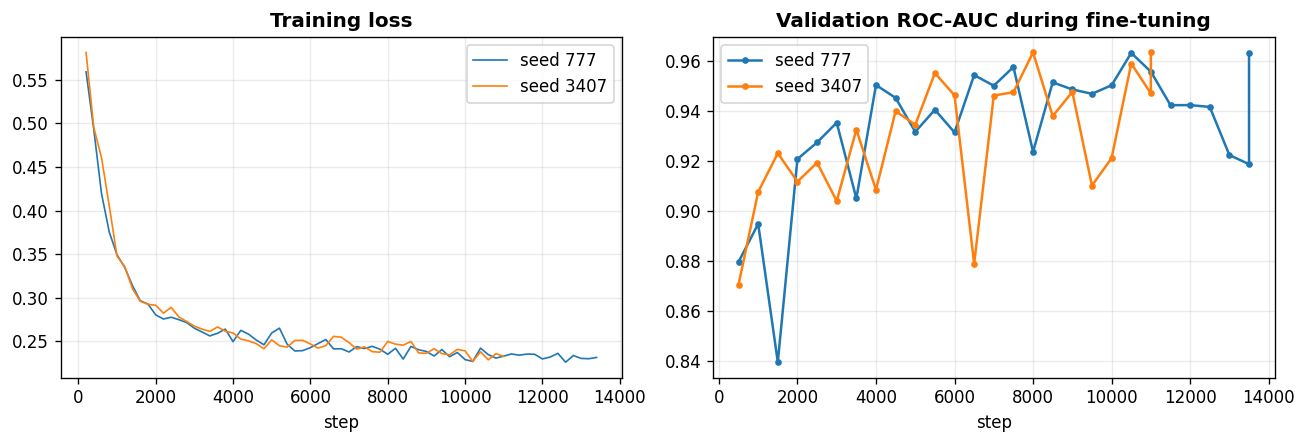

In [11]:
MEMBER_DIRS, FULL_RES, ALL_SEEDS = [], {}, []
for seed in PRETRAINED_SEEDS:
    hits = sorted(Path("/kaggle/input").rglob(f"finetuned_transformer/seed{seed}/model.safetensors")) if Path("/kaggle/input").exists() else []
    if not hits:
        print(f"Pretrained member seed{seed} not found - skipped"); continue
    out_dir = FINAL_MODEL_DIR / f"seed{seed}"
    shutil.copytree(hits[0].parent, out_dir, dirs_exist_ok=True)
    MEMBER_DIRS.append(out_dir); ALL_SEEDS.append(seed)
    print(f"Reused run-4 member seed={seed} from {hits[0].parent}")
for seed in NEW_SEEDS:
    print(f"\n===== Ensemble member seed={seed} =====")
    rng_aug = np.random.default_rng(seed + 7)
    mask = rng_aug.random(len(ft_train)) < NOISE_TRAIN_FRACTION
    ft_aug = ft_train.copy()
    ft_aug.loc[mask, "text"] = [asr_noise(t, rng_aug) for t in ft_train.loc[mask, "text"]]
    tr_dir, ev_dir = prepare_model_data(BEST_BACKBONE, ft_aug, val_eval, tag=f"full_s{seed}")
    fp32_dir = WORK_DIR / f"full_s{seed}_fp32"
    FULL_RES[seed] = run_ddp(BEST_BACKBONE, tr_dir, ev_dir, tag=f"full_s{seed}", save_dir=fp32_dir,
                             epochs=NUM_EPOCHS, max_steps=FULL_MAX_STEPS, seed=seed)
    out_dir = FINAL_MODEL_DIR / f"seed{seed}"
    _m = AutoModelForSequenceClassification.from_pretrained(fp32_dir)
    _m.half().save_pretrained(out_dir)
    AutoTokenizer.from_pretrained(fp32_dir).save_pretrained(out_dir)
    del _m, ft_aug; gc.collect()
    for p in (fp32_dir, WORK_DIR / f"full_s{seed}_ckpt", tr_dir):
        shutil.rmtree(p, ignore_errors=True)
    MEMBER_DIRS.append(out_dir); ALL_SEEDS.append(seed)
    print(f"Saved member -> {out_dir} ({sum(f.stat().st_size for f in out_dir.glob('*'))/1e6:.0f} MB) | best val ROC-AUC {FULL_RES[seed]['best_metric']}")
full_res = next(iter(FULL_RES.values()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for seed, res in FULL_RES.items():
    hist = pd.DataFrame([h for h in res["log_history"] if "eval_roc_auc" in h])
    loss = pd.DataFrame([h for h in res["log_history"] if "loss" in h and "eval_loss" not in h])
    if len(loss):
        ax[0].plot(loss["step"], loss["loss"], lw=1, label=f"seed {seed}")
    if len(hist):
        ax[1].plot(hist["step"], hist["eval_roc_auc"], marker="o", ms=3, label=f"seed {seed}")
ax[0].set_title("Training loss", fontweight="bold"); ax[1].set_title("Validation ROC-AUC during fine-tuning", fontweight="bold")
for a in ax:
    a.set_xlabel("step"); a.legend()
plt.tight_layout(); fig.savefig(MODEL_OUT_DIR / f"{MODEL_SLUG}_training_curve.png", dpi=200); plt.show()

## Section 8: Feature Extraction → PCA (≤ 50) → Classifier  *(teacher's rule)*
For every chunk we take the fine-tuned model's **768-d penultimate representation** (input of the final classification layer) and add the audio/time features (emotion one-hots, pace, confidence, timestamp). That is **> 50 features**, so we apply `StandardScaler` → **PCA** and train a **Logistic Regression** on the principal components. Everything is fitted on the held-out *head* calls only; the number of components (≤ 50) is chosen on validation. Inference runs on both GPUs in parallel (one model copy per GPU).

In [12]:
def final_linear(model):
    head = model.classifier
    if hasattr(head, "out_proj"):      # RoBERTa / XLM-R / HingRoBERTa
        return head.out_proj
    if isinstance(head, nn.Linear):    # BERT / MuRIL
        return head
    raise ValueError(f"Unknown classification head: {type(head)}")

def transformer_scores(model_dir, texts, batch_size=64):
    # Returns (P(fraud), penultimate features) for each text, using every visible GPU in parallel.
    texts = list(texts)
    tok0 = AutoTokenizer.from_pretrained(model_dir)
    ids, _ = encode_head_tail(tok0, texts)
    order = np.argsort([len(x) for x in ids], kind="stable")
    devices = [f"cuda:{i}" for i in range(N_GPUS)] or ["cpu"]
    parts = [order[i::len(devices)] for i in range(len(devices))]
    probs = np.full(len(texts), np.nan, dtype=np.float32)
    hidden = AutoConfig.from_pretrained(model_dir).hidden_size   # allocate BEFORE the threads start (no race)
    feats = np.full((len(texts), hidden), np.nan, dtype=np.float32)
    errors = []

    def work(dev, idx):
        try:
            tok = AutoTokenizer.from_pretrained(model_dir)
            m = AutoModelForSequenceClassification.from_pretrained(model_dir)
            m = (m.half() if dev.startswith("cuda") else m.float()).to(dev).eval()
            cap = {}
            hook = final_linear(m).register_forward_hook(lambda mod, inp, out: cap.__setitem__("x", inp[0]))
            for s in range(0, len(idx), batch_size):
                b = idx[s:s + batch_size]
                enc = tok.pad({"input_ids": [ids[j] for j in b]}, return_tensors="pt")
                with torch.no_grad():
                    logits = m(input_ids=enc["input_ids"].to(dev), attention_mask=enc["attention_mask"].to(dev)).logits.float()
                probs[b] = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
                feats[b] = cap["x"].float().cpu().numpy()
            hook.remove()
            del m
        except Exception as e:  # surface thread errors
            errors.append(e)

    threads = [threading.Thread(target=work, args=(d, p)) for d, p in zip(devices, parts)]
    [t.start() for t in threads]; [t.join() for t in threads]
    if errors:
        raise errors[0]
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    assert not np.isnan(probs).any() and not np.isnan(feats).any(), "some texts were not scored"
    return probs, feats

# Score every UNIQUE text once (head, validation, test, cross-domain, noisy test), then map back to chunks
t0 = time.time()
rng_noise = np.random.default_rng(RANDOM_SEED + 99)
SETS = {"head": head_df, "val": val_df, "test": test_df}
if cross_df is not None:
    SETS["cross"] = cross_df
TEXTS = {k: d["text"].reset_index(drop=True) for k, d in SETS.items()}
TEXTS["test_noisy"] = pd.Series([asr_noise(t, rng_noise) for t in test_df["text"]])
FRAMES = {**SETS, "test_noisy": test_df}   # the noisy copy shares labels/audio/time with test
all_text = pd.concat(list(TEXTS.values()), ignore_index=True)
codes, uniques = pd.factorize(all_text, sort=False)
print(f"{len(uniques):,} unique texts to score per ensemble member | sets: {list(TEXTS)}")

393,988 unique texts to score per ensemble member | sets: ['head', 'val', 'test', 'cross', 'test_noisy']


In [13]:
# Audio/time features — vocabulary and imputation fitted on the head calls only
PACE_MEDIAN = float(np.nanmedian(head_df["pace_num"])) if head_df["pace_num"].notna().any() else 1.0
CONF_MEDIAN = float(np.nanmedian(head_df["confidence_score"])) if head_df["confidence_score"].notna().any() else 1.0
TOP_DOM = sorted(head_df["dominant_emotion"].value_counts().head(TOP_N_EMOTIONS).index)
TOP_SEC = sorted(head_df["secondary_emotion"].value_counts().head(TOP_N_EMOTIONS).index)

def audio_frame(d):
    return pd.DataFrame({
        "dominant_emotion": d["dominant_emotion"].where(d["dominant_emotion"].isin(TOP_DOM), "Other"),
        "secondary_emotion": d["secondary_emotion"].where(d["secondary_emotion"].isin(TOP_SEC), "Other"),
        "pace_num": d["pace_num"].fillna(PACE_MEDIAN), "confidence_score": d["confidence_score"].fillna(CONF_MEDIAN),
        "chunk_timestamp": d["chunk_timestamp"]})

OHE = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32).fit(audio_frame(head_df)[["dominant_emotion", "secondary_emotion"]])

def full_features(text_feat, d):
    a = audio_frame(d)
    return np.hstack([text_feat, OHE.transform(a[["dominant_emotion", "secondary_emotion"]]),
                      a[["pace_num", "confidence_score", "chunk_timestamp"]].to_numpy(np.float32)]).astype(np.float32)

y_head, y_val, y_test = head_df["y"].to_numpy(), val_df["y"].to_numpy(), test_df["y"].to_numpy()
MEMBERS, SCORES_M, TFP_M = [], [], []
for seed, mdir in zip(ALL_SEEDS, MEMBER_DIRS):
    t0 = time.time()
    u_prob, u_feat = transformer_scores(mdir, uniques.tolist())
    FEAT, tfp, off = {}, {}, 0
    for name, t in TEXTS.items():
        sl = codes[off: off + len(t)]; off += len(t)
        FEAT[name], tfp[name] = u_feat[sl], u_prob[sl]
    del u_feat; gc.collect()
    X = {name: full_features(FEAT[name], FRAMES[name]) for name in FEAT}
    del FEAT; gc.collect()
    N_RAW_FEATURES = X["head"].shape[1]
    assert N_RAW_FEATURES > 50
    scaler = StandardScaler().fit(X["head"])
    XS = {k: scaler.transform(v).astype(np.float32) for k, v in X.items()}
    del X; gc.collect()
    grid_m = []
    for n in PCA_GRID:
        n = min(n, XS["head"].shape[0] - 1, XS["head"].shape[1])
        p_ = PCA(n_components=n, random_state=RANDOM_SEED).fit(XS["head"])
        c_ = LogisticRegression(max_iter=5000, random_state=RANDOM_SEED).fit(p_.transform(XS["head"]), y_head)
        grid_m.append({"n_components": n, "explained_var": float(p_.explained_variance_ratio_.sum()),
                       "val_roc_auc": float(roc_auc_score(y_val, c_.predict_proba(p_.transform(XS["val"]))[:, 1]))})
    gdf = pd.DataFrame(grid_m)
    n_sel = int(gdf[gdf["val_roc_auc"] >= gdf["val_roc_auc"].max() - 1e-3]["n_components"].min())
    assert n_sel <= 50
    pca_m = PCA(n_components=n_sel, random_state=RANDOM_SEED).fit(XS["head"])
    clf_m = LogisticRegression(max_iter=5000, random_state=RANDOM_SEED).fit(pca_m.transform(XS["head"]), y_head)
    sc = {k: clf_m.predict_proba(pca_m.transform(v))[:, 1] for k, v in XS.items()}
    del XS; gc.collect()
    head_path = MODEL_OUT_DIR / f"{MODEL_SLUG}_pca_head_seed{seed}.joblib"
    joblib.dump({"scaler": scaler, "pca": pca_m, "classifier": clf_m, "ohe": OHE, "pace_median": PACE_MEDIAN, "conf_median": CONF_MEDIAN,
                 "top_dominant_emotions": TOP_DOM, "top_secondary_emotions": TOP_SEC, "n_components": n_sel, "n_raw_features": N_RAW_FEATURES}, head_path)
    m_auc = float(roc_auc_score(y_val, sc["val"]))
    MEMBERS.append({"seed": seed, "weights_dir": FINAL_MODEL_DIR.name + f"/seed{seed}", "head": head_path.name, "n_components": n_sel,
                    "val_roc_auc": m_auc, "pca_grid": grid_m, "best_ft_val_roc_auc": FULL_RES.get(seed, {}).get("best_metric")})
    SCORES_M.append(sc); TFP_M.append(tfp)
    print(f"Member seed={seed}: raw {N_RAW_FEATURES} -> PCA {n_sel} (<= 50) | val ROC-AUC {m_auc:.4f} | {(time.time()-t0)/60:.1f} min")

from itertools import combinations
cands = []
for r in range(1, len(MEMBERS) + 1):
    for sub in combinations(range(len(MEMBERS)), r):
        auc = float(roc_auc_score(y_val, np.mean([SCORES_M[i]["val"] for i in sub], axis=0)))
        cands.append((auc, len(sub), sub))
        print(f"  members {[MEMBERS[i]['seed'] for i in sub]}: val ROC-AUC {auc:.4f}")
ENS_VAL_AUC, _, USE = max(cands)
USE = list(USE)
print(f"\nSelected on validation: members {[MEMBERS[i]['seed'] for i in USE]} (val ROC-AUC {ENS_VAL_AUC:.4f})")
MEMBERS = [MEMBERS[i] for i in USE]
SCORES = {k: np.mean([SCORES_M[i][k] for i in USE], axis=0) for k in SCORES_M[0]}
TFP = {k: np.mean([TFP_M[i][k] for i in USE], axis=0) for k in TFP_M[0]}
for name, d in SETS.items():
    d["tf_prob"] = TFP[name]
N_COMPONENTS = max(m["n_components"] for m in MEMBERS)
grid = [{"seed": m["seed"], "pca_grid": m["pca_grid"]} for m in MEMBERS]
score_val, score_test = SCORES["val"], SCORES["test"]
print(f"Final scorer: {len(MEMBERS)} member(s), each <= 50 PCA features (max {N_COMPONENTS}) | val ROC-AUC {roc_auc_score(y_val, score_val):.4f}")
score_val, score_test = SCORES["val"], SCORES["test"]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (515 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Member seed=42: raw 797 -> PCA 40 (<= 50) | val ROC-AUC 0.9422 | 12.5 min


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (515 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (9 outputs left out)

Member seed=3407: raw 797 -> PCA 20 (<= 50) | val ROC-AUC 0.9555 | 12.5 min
  members [42]: val ROC-AUC 0.9422
  members [1234]: val ROC-AUC 0.9527
  members [777]: val ROC-AUC 0.9551
  members [3407]: val ROC-AUC 0.9555


  members [42, 1234]: val ROC-AUC 0.9548
  members [42, 777]: val ROC-AUC 0.9554
  members [42, 3407]: val ROC-AUC 0.9560
  members [1234, 777]: val ROC-AUC 0.9601
  members [1234, 3407]: val ROC-AUC 0.9589


  members [777, 3407]: val ROC-AUC 0.9608
  members [42, 1234, 777]: val ROC-AUC 0.9589
  members [42, 1234, 3407]: val ROC-AUC 0.9585
  members [42, 777, 3407]: val ROC-AUC 0.9595
  members [1234, 777, 3407]: val ROC-AUC 0.9616


  members [42, 1234, 777, 3407]: val ROC-AUC 0.9606

Selected on validation: members [1234, 777, 3407] (val ROC-AUC 0.9616)
Final scorer: 3 member(s), each <= 50 PCA features (max 30) | val ROC-AUC 0.9616


## Section 9: Threshold Calibration, Risk-Velocity Reasoning Engine & Held-Out Test Evaluation
Same protocol as the team evaluator (so results go straight into the 5-model comparison table):
1. **Grid search on validation** for `τ_alert` (max F1); `τ_review = 0.8 · τ_alert`; `τ_velocity` = 95th percentile of |Δs| on validation.
2. **Forward-chaining rules:** `ALERT` if `s ≥ τ_alert` or (`s ≥ τ_review` and `Δs ≥ τ_velocity`); `REVIEW` if `s ≥ τ_review`; else `NORMAL`.
3. **Chunk-level & call-level** F1 / Precision / Recall / FPR / ROC-AUC / PR-AUC and **Median Time-to-Detection** on the untouched test set.

>>> OFFICIAL MODEL (<= 50 features after PCA) - team protocol on the OFFICIAL validation/test splits (comparable with the team table)


HELD-OUT TEST RESULTS - Ensemble of 3 fine-tuned hing-roberta + PCA(<=50) + LR
Chunk-Level -> F1: 0.8935 | Prec: 0.8777 | Rec: 0.9098 | FPR: 0.2257 | ROC-AUC: 0.9361 | PR-AUC: 0.9636
Call-Level  -> F1: 0.9801 | Prec: 0.9901 | Rec: 0.9703 | FPR: 0.8776 | ROC-AUC: 0.7974 | PR-AUC: 0.9972
Early Alert -> Median Time-to-Detection: 48.0s | thresholds {'tau_review': 0.0529, 'tau_alert': 0.0661, 'tau_velocity': 0.2315}
Extra       -> {'val_f1_at_tau_alert': 0.9072, 'test_legit_calls': 49.0, 'test_fraud_calls': 4450.0, 'fraud_calls_alerted_pct': 97.0337, 'median_alert_lead_before_label_flip_sec': 0.0}


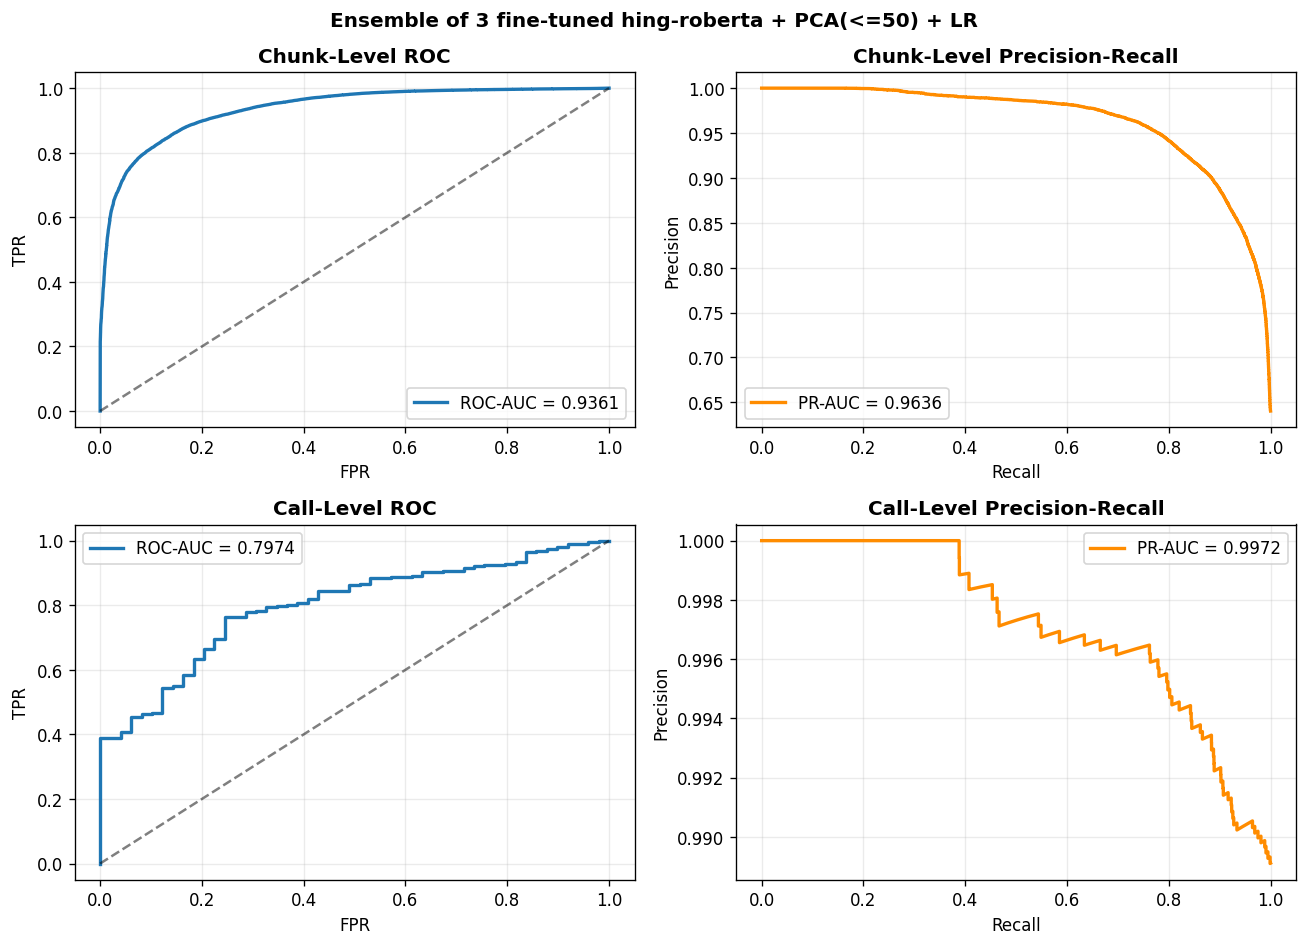


>>> Reference only: transformer's own softmax head (768-d, no PCA) - NOT the submitted model


HELD-OUT TEST RESULTS - Fine-tuned hing-roberta (raw head, reference)
Chunk-Level -> F1: 0.9010 | Prec: 0.8930 | Rec: 0.9091 | FPR: 0.1940 | ROC-AUC: 0.9419 | PR-AUC: 0.9696
Call-Level  -> F1: 0.9791 | Prec: 0.9901 | Rec: 0.9683 | FPR: 0.8776 | ROC-AUC: 0.7864 | PR-AUC: 0.9969
Early Alert -> Median Time-to-Detection: 48.0s | thresholds {'tau_review': 0.1706, 'tau_alert': 0.2132, 'tau_velocity': 0.2607}
Extra       -> {'val_f1_at_tau_alert': 0.911, 'test_legit_calls': 49.0, 'test_fraud_calls': 4450.0, 'fraud_calls_alerted_pct': 96.8315, 'median_alert_lead_before_label_flip_sec': 0.0}


In [14]:
def calibrate_thresholds(val_scores, yv):
    best_f1, best_tau = -1.0, float(np.median(val_scores))
    for tau in np.quantile(val_scores, np.linspace(0.05, 0.99, 180)):
        f = f1_score(yv, (val_scores >= tau).astype(np.int8), zero_division=0)
        if f > best_f1:
            best_f1, best_tau = float(f), float(tau)
    tau_velocity = float(np.percentile(np.abs(np.diff(val_scores)), 95))
    return {"tau_review": 0.8 * best_tau, "tau_alert": best_tau, "tau_velocity": tau_velocity, "val_f1": best_f1}

def reasoning_engine(meta, scores, th):
    res = meta[["conversation_uid", "domain", "chunk_timestamp", "y"]].copy()
    res["score"] = scores
    same_call = res["conversation_uid"] == res["conversation_uid"].shift(1)
    res["risk_velocity"] = np.where(same_call, res["score"] - res["score"].shift(1), 0.0)
    alert = (res["score"] >= th["tau_alert"]) | ((res["score"] >= th["tau_review"]) & (res["risk_velocity"] >= th["tau_velocity"]))
    review = (~alert) & (res["score"] >= th["tau_review"])
    res["alert_level"] = np.where(alert, "ALERT", np.where(review, "REVIEW", "NORMAL"))
    res["pred"] = alert.astype(np.int8)
    return res

def evaluate(model_name, val_frame, val_scores, test_frame, test_scores, n_features, save=True):
    th = calibrate_thresholds(val_scores, val_frame["y"].to_numpy())
    s = reasoning_engine(test_frame, test_scores, th)
    yt, yp = s["y"].to_numpy(), s["pred"].to_numpy()
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    chunk = {"chunk_f1": f1_score(yt, yp, zero_division=0), "chunk_precision": precision_score(yt, yp, zero_division=0),
             "chunk_recall": recall_score(yt, yp, zero_division=0), "chunk_fpr": fp / max(fp + tn, 1),
             "chunk_roc_auc": roc_auc_score(yt, s["score"]), "chunk_pr_auc": average_precision_score(yt, s["score"])}
    calls = s.groupby("conversation_uid", sort=False).agg(y_true=("y", "last"), max_score=("score", "max"), any_alert=("pred", "max"))
    ctn, cfp, cfn, ctp = confusion_matrix(calls["y_true"], calls["any_alert"], labels=[0, 1]).ravel()
    caught = s[(s["y"] == 1) & (s["pred"] == 1)].groupby("conversation_uid")["chunk_timestamp"].min()
    flip = s[s["y"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    any_alert_ts = s[s["pred"] == 1].groupby("conversation_uid")["chunk_timestamp"].min()
    lead = (flip - any_alert_ts.reindex(flip.index)).dropna()
    call = {"call_f1": f1_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_precision": precision_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_recall": recall_score(calls["y_true"], calls["any_alert"], zero_division=0),
            "call_fpr": cfp / max(cfp + ctn, 1),
            "call_roc_auc": roc_auc_score(calls["y_true"], calls["max_score"]) if calls["y_true"].nunique() > 1 else float("nan"),
            "call_pr_auc": average_precision_score(calls["y_true"], calls["max_score"]),
            "median_ttd_seconds": float(caught.median()) if len(caught) else None}
    r4 = lambda d: {k: (None if v is None or (isinstance(v, (float, np.floating)) and np.isnan(v)) else round(float(v), 4)) for k, v in d.items()}
    results = {"model_name": model_name, "pca_dimensions": int(n_features),
               "thresholds": r4({k: th[k] for k in ("tau_review", "tau_alert", "tau_velocity")}),
               "chunk_level": r4(chunk), "call_level": r4(call),
               "extra": r4({"val_f1_at_tau_alert": th["val_f1"], "test_legit_calls": int((calls["y_true"] == 0).sum()),
                            "test_fraud_calls": int((calls["y_true"] == 1).sum()),
                            "fraud_calls_alerted_pct": 100 * float(calls.loc[calls["y_true"] == 1, "any_alert"].mean()),
                            "median_alert_lead_before_label_flip_sec": float(lead.median()) if len(lead) else None})}
    print("=" * 74)
    print(f"HELD-OUT TEST RESULTS - {model_name}")
    print("=" * 74)
    c, k = results["chunk_level"], results["call_level"]
    print(f"Chunk-Level -> F1: {c['chunk_f1']:.4f} | Prec: {c['chunk_precision']:.4f} | Rec: {c['chunk_recall']:.4f} | FPR: {c['chunk_fpr']:.4f} | ROC-AUC: {c['chunk_roc_auc']:.4f} | PR-AUC: {c['chunk_pr_auc']:.4f}")
    print(f"Call-Level  -> F1: {k['call_f1']:.4f} | Prec: {k['call_precision']:.4f} | Rec: {k['call_recall']:.4f} | FPR: {k['call_fpr']:.4f} | ROC-AUC: {k['call_roc_auc']} | PR-AUC: {k['call_pr_auc']:.4f}")
    print(f"Early Alert -> Median Time-to-Detection: {k['median_ttd_seconds']}s | thresholds {results['thresholds']}")
    print(f"Extra       -> {results['extra']}")
    if save:
        with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_metrics.json", "w", encoding="utf-8") as f:
            json.dump(results, f, indent=2)
        fig, ax = plt.subplots(2, 2, figsize=(11, 8))
        for row, (yy, ss, lvl) in enumerate([(yt, s["score"], "Chunk"), (calls["y_true"], calls["max_score"], "Call")]):
            fpr_c, tpr_c, _ = roc_curve(yy, ss); pr_c, rc_c, _ = precision_recall_curve(yy, ss)
            ax[row, 0].plot(fpr_c, tpr_c, lw=2, label=f"ROC-AUC = {roc_auc_score(yy, ss):.4f}"); ax[row, 0].plot([0, 1], [0, 1], "k--", alpha=.5)
            ax[row, 0].set_title(f"{lvl}-Level ROC", fontweight="bold"); ax[row, 0].set_xlabel("FPR"); ax[row, 0].set_ylabel("TPR"); ax[row, 0].legend()
            ax[row, 1].plot(rc_c, pr_c, lw=2, color="darkorange", label=f"PR-AUC = {average_precision_score(yy, ss):.4f}")
            ax[row, 1].set_title(f"{lvl}-Level Precision-Recall", fontweight="bold"); ax[row, 1].set_xlabel("Recall"); ax[row, 1].set_ylabel("Precision"); ax[row, 1].legend()
        fig.suptitle(model_name, fontweight="bold"); plt.tight_layout()
        fig.savefig(MODEL_OUT_DIR / f"{MODEL_SLUG}_curves.png", dpi=200); plt.show()
    return results, s, th

short = BEST_BACKBONE.split("/")[-1]
MODEL_NAME = (f"Ensemble of {len(MEMBERS)} fine-tuned {short} + PCA(<=50) + LR" if len(MEMBERS) > 1 else f"Fine-tuned {short} + PCA-{N_COMPONENTS} + LR")
vo, to = val_df["official"].to_numpy(bool), test_df["official"].to_numpy(bool)
VAL_OFF, TEST_OFF = val_df[vo].reset_index(drop=True), test_df[to].reset_index(drop=True)
print(">>> OFFICIAL MODEL (<= 50 features after PCA) - team protocol on the OFFICIAL validation/test splits (comparable with the team table)")
results, test_stream, THRESHOLDS = evaluate(MODEL_NAME, VAL_OFF, score_val[vo], TEST_OFF, score_test[to], n_features=N_COMPONENTS, save=True)
print("\n>>> Reference only: transformer's own softmax head (768-d, no PCA) - NOT the submitted model")
ref_results, _, _ = evaluate(f"Fine-tuned {short} (raw head, reference)", VAL_OFF, val_df["tf_prob"].to_numpy()[vo], TEST_OFF,
                             test_df["tf_prob"].to_numpy()[to], n_features=768, save=False)

## Section 9b: Deployment Alert Policy — false alarms on legitimate calls, unseen scam types, ASR noise
The team protocol above scores single chunks. A live product must instead decide **per call, in real time**, without crying wolf on normal calls. Policy (research-backed: consecutive-turn rules, smoothing, latching, thresholds fixed on a calibration set for a false-alarm target):
1. `ema_t = α·p_t + (1−α)·ema_{t−1}` (smoothed P(fraud) of each 3-second chunk).
2. **ALERT** when the last *k* smoothed scores are all ≥ `τ_alert`; once raised it stays raised for the call (latched).
3. **REVIEW** ("watching") when `ema_t ≥ τ_review`.
4. α ∈ {1.0, 0.6, 0.3}, *k* ∈ {1, 2, 3} and `τ_alert` are chosen on **validation** to maximise scam calls caught subject to **≤ 10 % of legitimate calls alerted**; `τ_review` lets at most 30 % of legitimate calls enter REVIEW. Then everything is frozen and applied once to test, cross-domain and noisy test.

Selected policy (validation): {'alpha': 0.3, 'k': 1, 'tau_alert': 0.014, 'tau_review': 0.0064, 'target_legit_false_alarm': 0.1, 'review_legit_rate': 0.3, 'selected_on': 'validation'}
Validation at selected policy: {'alpha': 0.3, 'k': 1.0, 'tau_alert': 0.014, 'legit_false_alarm_rate': 0.0957, 'scam_detection_rate': 0.9947, 'call_f1': 0.9867, 'median_time_to_alert_sec': 36.0}
Stricter option (<= 5 % legit false alarms on validation): {'alpha': 0.6, 'k': 2.0, 'tau_alert': 0.0511, 'legit_false_alarm_rate': 0.0493, 'scam_detection_rate': 0.9776, 'call_f1': 0.9831, 'median_time_to_alert_sec': 42.0}



=== DEPLOYMENT METRICS (policy frozen on validation) ===
                            legit_calls scam_calls legit_false_alarm_rate legit_false_alarm_ci95 clear_normal_false_alarm_rate ambiguous_normal_false_alarm_rate scam_detection_rate scam_detection_ci95 call_precision call_f1 median_time_to_alert_sec median_alert_lead_vs_label_flip_sec
validation                         1014       4499                 0.0957       (0.0791, 0.1153)                        0.0847                            0.1173              0.9947    (0.9921, 0.9964)         0.9788  0.9867                     36.0                                 0.0
test                               1014       4499                 0.0957       (0.0791, 0.1153)                         0.073                            0.1399              0.9907    (0.9874, 0.9931)         0.9787  0.9846                     36.0                                 0.0
cross_domain_unseen_scams             0       1000                    NaN           (No

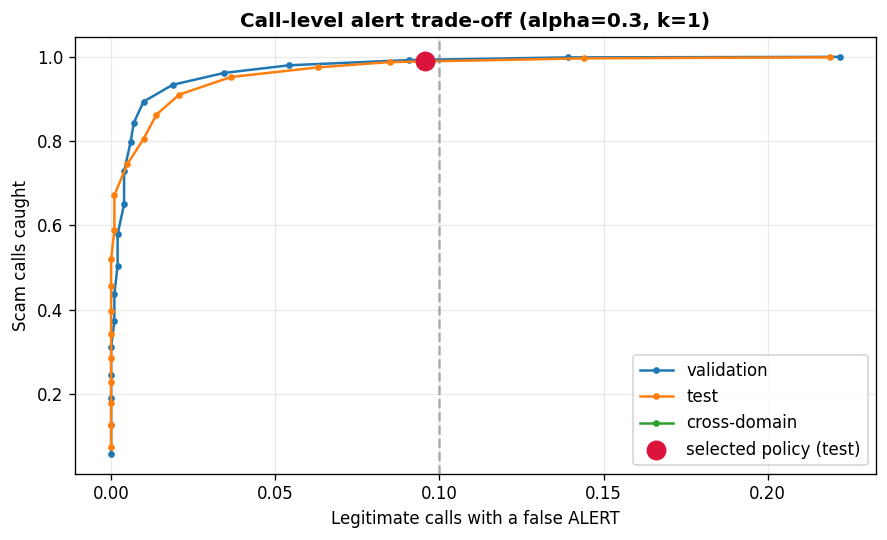

In [15]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (None, None)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (round(float(c - h), 4), round(float(c + h), 4))

def smoothed(frame, scores, alpha):
    d = pd.DataFrame({"uid": frame["conversation_uid"].to_numpy(), "s": np.asarray(scores, dtype=np.float64)})
    if alpha >= 1.0:
        return d["s"].to_numpy()
    return d.groupby("uid", sort=False)["s"].transform(lambda x: x.ewm(alpha=alpha, adjust=False).mean()).to_numpy()

def consecutive_min(frame, ema, k):
    if k == 1:
        return ema
    d = pd.DataFrame({"uid": frame["conversation_uid"].to_numpy(), "e": ema})
    return d.groupby("uid", sort=False)["e"].transform(lambda x: x.rolling(k, min_periods=k).min()).fillna(-1.0).to_numpy()

def call_outcomes(frame, signal, tau):
    d = pd.DataFrame({"uid": frame["conversation_uid"].to_numpy(), "ts": frame["chunk_timestamp"].to_numpy(),
                      "y": frame["y"].to_numpy(), "hit": signal >= tau, "lab": frame["scam_call"].to_numpy(), "case": frame["case_type"].to_numpy()})
    calls = d.groupby("uid", sort=False).agg(label=("lab", "first"), case=("case", "first"), alerted=("hit", "max"), duration=("ts", "max"))
    calls["first_alert"] = d[d["hit"]].groupby("uid")["ts"].min()
    calls["flip"] = d[d["y"] == 1].groupby("uid")["ts"].min()
    return calls

def summarize(calls):
    legit, scam = calls[calls["label"] == 0], calls[calls["label"] == 1]
    fp, tp = int(legit["alerted"].sum()), int(scam["alerted"].sum())
    det = tp / len(scam) if len(scam) else float("nan")
    prec = tp / (tp + fp) if tp + fp else float("nan")
    caught = scam[scam["alerted"]]
    extra = {}
    for case_name, key in (("Clear Normal", "clear_normal"), ("Ambiguous but Ultimately Normal", "ambiguous_normal")):
        sub = legit[legit["case"] == case_name]
        extra[f"{key}_calls"] = len(sub)
        extra[f"{key}_false_alarm_rate"] = float(sub["alerted"].mean()) if len(sub) else float("nan")
    return {**extra, "legit_calls": len(legit), "scam_calls": len(scam),
            "legit_false_alarm_rate": fp / len(legit) if len(legit) else float("nan"), "legit_false_alarm_ci95": wilson(fp, len(legit)),
            "scam_detection_rate": det, "scam_detection_ci95": wilson(tp, len(scam)), "call_precision": prec,
            "call_f1": 2 * prec * det / (prec + det) if prec == prec and det == det and prec + det > 0 else float("nan"),
            "median_time_to_alert_sec": float(caught["first_alert"].median()) if len(caught) else None,
            "median_alert_lead_vs_label_flip_sec": float((caught["flip"] - caught["first_alert"]).median()) if len(caught) else None,
            "share_alerts_before_label_flip": float((caught["first_alert"] < caught["flip"]).mean()) if len(caught) else None}

def r4(d):
    return {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) and v == v else v) for k, v in d.items()}

# ---- grid search on VALIDATION only
TAUS = np.unique(np.quantile(score_val, np.linspace(0.30, 0.999, 80)))
rows = []
for alpha in POLICY_ALPHAS:
    ema_v = smoothed(val_df, score_val, alpha)
    for k in POLICY_KS:
        sig_v = consecutive_min(val_df, ema_v, k)
        for tau in TAUS:
            sm = summarize(call_outcomes(val_df, sig_v, tau))
            rows.append({"alpha": alpha, "k": k, "tau_alert": float(tau), **{m: sm[m] for m in ("legit_false_alarm_rate", "scam_detection_rate", "call_f1", "median_time_to_alert_sec")}})
policy_grid = pd.DataFrame(rows)

def pick(target):
    ok = policy_grid[policy_grid["legit_false_alarm_rate"] <= target]
    if not len(ok):
        return policy_grid.sort_values(["legit_false_alarm_rate", "scam_detection_rate"], ascending=[True, False]).iloc[0]
    return ok.sort_values(["scam_detection_rate", "median_time_to_alert_sec"], ascending=[False, True]).iloc[0]

best = pick(TARGET_LEGIT_FALSE_ALARM)
ALPHA, K, TAU_ALERT = float(best["alpha"]), int(best["k"]), float(best["tau_alert"])
ema_v = smoothed(val_df, score_val, ALPHA)
legit_ids = val_df.groupby("conversation_uid", sort=False)["scam_call"].first()
legit_ids = set(legit_ids[legit_ids == 0].index)
legit_peak = pd.Series(ema_v).groupby(val_df["conversation_uid"].to_numpy()).max()
legit_peak = legit_peak[legit_peak.index.isin(legit_ids)]
cands = [t for t in TAUS if t <= TAU_ALERT and (legit_peak >= t).mean() <= REVIEW_LEGIT_RATE]
TAU_REVIEW = float(min(cands)) if cands else TAU_ALERT
POLICY = {"alpha": ALPHA, "k": K, "tau_alert": TAU_ALERT, "tau_review": TAU_REVIEW,
          "target_legit_false_alarm": TARGET_LEGIT_FALSE_ALARM, "review_legit_rate": REVIEW_LEGIT_RATE, "selected_on": "validation"}
alt5 = pick(0.05)
POLICY_STRICT = {"alpha": float(alt5["alpha"]), "k": int(alt5["k"]), "tau_alert": float(alt5["tau_alert"]),
                 "tau_review": min(TAU_REVIEW, float(alt5["tau_alert"])), "target_legit_false_alarm": 0.05, "selected_on": "validation"}
print("Selected policy (validation):", r4(POLICY))
print("Validation at selected policy:", r4(best.to_dict()))
print("Stricter option (<= 5 % legit false alarms on validation):", r4(alt5.to_dict()))

# ---- apply the frozen policy once to every held-out set
def apply_policy(frame, scores, pol):
    sig = consecutive_min(frame, smoothed(frame, scores, pol["alpha"]), pol["k"])
    return summarize(call_outcomes(frame, sig, pol["tau_alert"]))

DEPLOY = {"validation": apply_policy(val_df, score_val, POLICY), "test": apply_policy(test_df, score_test, POLICY)}
if cross_df is not None:
    DEPLOY["cross_domain_unseen_scams"] = apply_policy(cross_df, SCORES["cross"], POLICY)
DEPLOY["test_asr_noise"] = apply_policy(test_df, SCORES["test_noisy"], POLICY)
DEPLOY["test_naive_single_chunk_0.5"] = apply_policy(test_df, score_test, {"alpha": 1.0, "k": 1, "tau_alert": 0.5})
DEPLOY["test_stricter_5pct_policy"] = apply_policy(test_df, score_test, {"alpha": float(alt5["alpha"]), "k": int(alt5["k"]), "tau_alert": float(alt5["tau_alert"])})
deploy_table = pd.DataFrame({k: r4(v) for k, v in DEPLOY.items()}).T
cols = ["legit_calls", "scam_calls", "legit_false_alarm_rate", "legit_false_alarm_ci95", "clear_normal_false_alarm_rate", "ambiguous_normal_false_alarm_rate", "scam_detection_rate", "scam_detection_ci95",
        "call_precision", "call_f1", "median_time_to_alert_sec", "median_alert_lead_vs_label_flip_sec"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print("\n=== DEPLOYMENT METRICS (policy frozen on validation) ===")
print(deploy_table[cols].to_string())

# ---- calibration of the chunk-level probabilities (test, all chunks)
def ece(y, p, bins=10):
    e, edges = 0.0, np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi if hi < 1 else p <= hi)
        if m.any():
            e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)
CALIBRATION = {"test_chunk_ece": round(ece(y_test, score_test), 4), "test_chunk_brier": round(float(np.mean((score_test - y_test) ** 2)), 4),
               "test_chunk_roc_auc_all": round(float(roc_auc_score(y_test, score_test)), 4),
               "test_noisy_chunk_roc_auc_all": round(float(roc_auc_score(y_test, SCORES["test_noisy"])), 4)}
if cross_df is not None and cross_df["y"].nunique() > 1:
    CALIBRATION["cross_domain_chunk_roc_auc"] = round(float(roc_auc_score(cross_df["y"], SCORES["cross"])), 4)
print("\nCalibration / robustness (chunk level):", CALIBRATION)

# ---- trade-off plot for the selected alpha/k
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, frame, sc in [("validation", val_df, score_val), ("test", test_df, score_test)] + ([("cross-domain", cross_df, SCORES["cross"])] if cross_df is not None else []):
    sig = consecutive_min(frame, smoothed(frame, sc, ALPHA), K)
    pts = [summarize(call_outcomes(frame, sig, t)) for t in TAUS[::4]]
    ax.plot([p["legit_false_alarm_rate"] for p in pts], [p["scam_detection_rate"] for p in pts], marker=".", label=name)
sel = DEPLOY["test"]
ax.scatter([sel["legit_false_alarm_rate"]], [sel["scam_detection_rate"]], s=120, c="crimson", zorder=5, label="selected policy (test)")
ax.axvline(TARGET_LEGIT_FALSE_ALARM, ls="--", c="grey", alpha=.6)
ax.set_xlabel("Legitimate calls with a false ALERT"); ax.set_ylabel("Scam calls caught")
ax.set_title(f"Call-level alert trade-off (alpha={ALPHA}, k={K})", fontweight="bold"); ax.legend()
plt.tight_layout(); fig.savefig(MODEL_OUT_DIR / f"{MODEL_SLUG}_alert_policy.png", dpi=200); plt.show()
with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_deployment.json", "w", encoding="utf-8") as f:
    json.dump({"policy": POLICY, "deployment": {k: r4(v) for k, v in DEPLOY.items()}, "calibration": CALIBRATION}, f, indent=2, default=str)

## Section 10: Save Everything for Reuse (no retraining) + Deployment Module
* `outputs/models/finetuned_transformer/` — fine-tuned weights (fp16 `safetensors`) + tokenizer (**large: kept out of git**; stored as Kaggle notebook output + local copy).
* `outputs/models/finetuned_transformer_pca_head.joblib` — scaler, PCA, classifier, one-hot encoder, imputation values.
* `outputs/models/finetuned_transformer_config.json` — backbone, truncation, alert policy, thresholds, all selection results.
* `src/fraud_detector.py` — **the module the frontend imports**: `FraudDetector` (batch scoring) and `CallSession` (live 3-second updates → NORMAL / REVIEW / ALERT). Verified below to reproduce the notebook's scores and alert decisions exactly, and benchmarked for latency.

In [16]:
config = {"model_name": MODEL_NAME, "backbone": BEST_BACKBONE, "members": MEMBERS, "ensemble_val_roc_auc": ENS_VAL_AUC, "max_len": MAX_LEN,
          "head_tokens": HEAD_TOKENS, "alert_policy": POLICY, "alert_policy_strict": POLICY_STRICT, "team_protocol_thresholds": THRESHOLDS,
          "pca_components": N_COMPONENTS, "n_raw_features": N_RAW_FEATURES, "bakeoff": bakeoff_df.to_dict(orient="records"),
          "pca_grid": grid, "training": {str(sd): {k: r_[k] for k in ("world_size", "train_runtime_sec", "global_step", "best_metric")} for sd, r_ in FULL_RES.items()},
          "training_recipe": {"lr": LEARNING_RATE, "label_smoothing": LABEL_SMOOTHING, "epochs": NUM_EPOCHS, "eval_steps": EVAL_STEPS,
                              "patience": EARLY_STOP_PATIENCE, "train_chunks": len(ft_train), "asr_noise_fraction": NOISE_TRAIN_FRACTION, "hard_negative_dup": HARD_NEG_DUP, "seeds": ALL_SEEDS},
          "splits": {"held_out_legit_val_calls": len(hold_val_uids), "held_out_legit_test_calls": len(hold_test_uids)},
          "deployment": {k: r4(v) for k, v in DEPLOY.items()}, "calibration": CALIBRATION,
          "inputs": MODEL_INPUT_COLS, "label": "per-chunk final_verdict (YES=1)", "random_seed": RANDOM_SEED, "smoke": SMOKE}
with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, default=str)

MODULE_SRC = r'''
# fraud_detector.py - real-time Hinglish phone-scam detector
# Fine-tuned HingRoBERTa features (768-d) + audio/time features -> StandardScaler -> PCA (<= 50) -> Logistic Regression,
# plus a call-level alert policy (EMA smoothing, k consecutive high-risk chunks, latched ALERT, REVIEW band).
#
# Usage:
#   from fraud_detector import FraudDetector, CallSession
#   det = FraudDetector("outputs/models/finetuned_transformer_config.json")   # loads every ensemble member listed in the config
#   call = CallSession(det)
#   state = call.update(cumulative_text, audio_analysis_json, timestamp_seconds)   # every ~3 s
#   state["level"] -> "NORMAL" | "REVIEW" | "ALERT"; state["score"] -> P(fraud) of this chunk
import json
import math
import re
from collections import deque

import joblib
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

PACE_MAP = {"slow": 0.0, "medium": 1.0, "fast": 2.0}


def _is_missing(v):
    return v is None or (isinstance(v, float) and math.isnan(v))


def _parse_audio(val):
    if isinstance(val, dict):
        return val
    if _is_missing(val):
        return {}
    try:
        out = json.loads(str(val))
        return out if isinstance(out, dict) else {}
    except (ValueError, TypeError):
        return {}


def _clean_text(text):
    return "" if _is_missing(text) else re.sub(r"[ \t]+", " ", str(text)).strip()


def _emotion(v):
    if _is_missing(v):
        return "Unknown"
    s = str(v).strip()
    return s if s else "Unknown"


def _number(v):
    try:
        x = float(v)
    except (TypeError, ValueError):
        return float("nan")
    return x


class FraudDetector:
    # Ensemble: P(fraud) = mean over members of each member's PCA(<=50)+LR probability.
    def __init__(self, config_path, device=None, batch_size=32):
        import os
        with open(config_path, encoding="utf-8") as f:
            self.config = json.load(f)
        base = os.path.dirname(os.path.abspath(config_path))
        self.members = [_Member(os.path.join(base, m["weights_dir"]), os.path.join(base, m["head"]), self.config, device, batch_size)
                        for m in self.config["members"]]
        self.device = self.members[0].device

    def score(self, texts, audio_jsons, timestamps):
        return np.mean([m.score(texts, audio_jsons, timestamps) for m in self.members], axis=0)


class _Member:
    def __init__(self, model_dir, head_path, config, device=None, batch_size=32):
        self.config = config
        self.head = joblib.load(head_path)
        self.device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
        self.batch_size = batch_size
        self.tok = AutoTokenizer.from_pretrained(model_dir)
        model = AutoModelForSequenceClassification.from_pretrained(model_dir)
        model = model.half() if self.device.startswith("cuda") else model.float()
        self.model = model.to(self.device).eval()
        cls = self.model.classifier
        self._final = cls.out_proj if hasattr(cls, "out_proj") else cls
        probe = "namaste hello world"
        with_sp, without = self.tok(probe)["input_ids"], self.tok(probe, add_special_tokens=False)["input_ids"]
        for i in range(len(with_sp) - len(without) + 1):
            if with_sp[i:i + len(without)] == without:
                self._prefix, self._suffix = with_sp[:i], with_sp[i + len(without):]
                break
        else:
            raise ValueError("Could not infer the special-token template")
        self.max_len, self.head_tokens = int(self.config["max_len"]), int(self.config["head_tokens"])

    def _encode(self, texts):
        body = self.max_len - len(self._prefix) - len(self._suffix)
        out = []
        for ids in self.tok(list(texts), add_special_tokens=False, truncation=False)["input_ids"]:
            if len(ids) > body:
                ids = ids[:self.head_tokens] + ids[-(body - self.head_tokens):]
            out.append(self._prefix + list(ids) + self._suffix)
        return out

    @torch.no_grad()
    def text_features(self, texts):
        ids = self._encode(texts)
        feats = np.zeros((len(ids), self._final.in_features), dtype=np.float32)
        cap = {}
        hook = self._final.register_forward_hook(lambda mod, inp, out: cap.__setitem__("x", inp[0]))
        try:
            order = np.argsort([len(x) for x in ids], kind="stable")
            for s in range(0, len(order), self.batch_size):
                b = order[s:s + self.batch_size]
                enc = self.tok.pad({"input_ids": [ids[j] for j in b]}, return_tensors="pt")
                self.model(input_ids=enc["input_ids"].to(self.device), attention_mask=enc["attention_mask"].to(self.device))
                feats[b] = cap["x"].float().cpu().numpy()
        finally:
            hook.remove()
        return feats

    def features(self, texts, audio_jsons, timestamps):
        h = self.head
        texts = [_clean_text(t) for t in texts]
        audio = [_parse_audio(a) for a in audio_jsons]
        dom = [_emotion(a.get("dominant_emotion")) for a in audio]
        sec = [_emotion(a.get("secondary_emotion")) for a in audio]
        emo = pd.DataFrame({"dominant_emotion": [d if d in h["top_dominant_emotions"] else "Other" for d in dom],
                            "secondary_emotion": [d if d in h["top_secondary_emotions"] else "Other" for d in sec]})
        pace = [PACE_MAP.get(str(a.get("pace")).strip().lower(), float("nan")) for a in audio]
        conf = [_number(a.get("confidence_score")) for a in audio]
        conf = [min(max(c, 0.0), 1.0) if not math.isnan(c) else float("nan") for c in conf]
        ts = [_number(t) for t in timestamps]
        num = np.array([[h["pace_median"] if math.isnan(p) else p, h["conf_median"] if math.isnan(c) else c,
                         0.0 if math.isnan(t) else max(t, 0.0)] for p, c, t in zip(pace, conf, ts)], dtype=np.float32)
        return np.hstack([self.text_features(texts), h["ohe"].transform(emo), num]).astype(np.float32)

    def score(self, texts, audio_jsons, timestamps):
        h = self.head
        xs = h["scaler"].transform(self.features(texts, audio_jsons, timestamps)).astype(np.float32)
        return h["classifier"].predict_proba(h["pca"].transform(xs))[:, 1]


class CallSession:
    def __init__(self, detector, policy=None):
        p = dict(policy or detector.config["alert_policy"])
        self.detector = detector
        self.alpha, self.k = float(p["alpha"]), int(p["k"])
        self.tau_alert, self.tau_review = float(p["tau_alert"]), float(p["tau_review"])
        self.reset()

    def reset(self):
        self.ema, self.window = None, deque(maxlen=self.k)
        self.alerted, self.first_alert_ts, self.history = False, None, []

    def update_score(self, score, timestamp):
        score = float(score)
        prev = self.ema
        self.ema = score if prev is None else self.alpha * score + (1.0 - self.alpha) * prev
        self.window.append(self.ema)
        if not self.alerted and len(self.window) == self.k and min(self.window) >= self.tau_alert:
            self.alerted, self.first_alert_ts = True, float(timestamp)
        level = "ALERT" if self.alerted else ("REVIEW" if self.ema >= self.tau_review else "NORMAL")
        state = {"timestamp": float(timestamp), "score": score, "smoothed_score": self.ema,
                 "risk_velocity": 0.0 if prev is None else self.ema - prev, "level": level,
                 "alerted": self.alerted, "first_alert_ts": self.first_alert_ts}
        self.history.append(state)
        return state

    def update(self, cumulative_text, audio_json, timestamp):
        return self.update_score(self.detector.score([cumulative_text], [audio_json], [timestamp])[0], timestamp)
'''
SRC_DIR = BASE_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)
(SRC_DIR / "fraud_detector.py").write_text(MODULE_SRC.lstrip(), encoding="utf-8")
spec = importlib.util.spec_from_file_location("fraud_detector", SRC_DIR / "fraud_detector.py")
fd = importlib.util.module_from_spec(spec); spec.loader.exec_module(fd)

det = fd.FraudDetector(MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json")

# Check 1: the module reproduces the notebook's chunk scores
idx = np.random.default_rng(0).choice(len(val_df), size=min(300, len(val_df)), replace=False)
sub = val_df.iloc[idx]
m_scores = det.score(sub["text"].tolist(), sub["audio_json"].tolist(), sub["chunk_timestamp"].tolist())
max_diff = float(np.max(np.abs(m_scores - score_val[idx])))
print(f"Check 1 - score reproduction: max |difference| over {len(idx)} validation chunks = {max_diff:.2e}")
assert max_diff < 1e-2, "Module does not reproduce the notebook scores"

# Check 2: CallSession reproduces the vectorised alert policy exactly (same scores, chunk by chunk)
calls_ck = list(dict.fromkeys(val_df["conversation_uid"]))[:60]
mism = 0
for uid in calls_ck:
    cf = val_df[val_df["conversation_uid"] == uid]
    sc = score_val[cf.index.to_numpy()]
    sess = fd.CallSession(det)
    for s_, t_ in zip(sc, cf["chunk_timestamp"]):
        st = sess.update_score(s_, t_)
    sig = consecutive_min(cf, smoothed(cf, sc, ALPHA), K)
    vec_alert = bool((sig >= TAU_ALERT).any())
    vec_first = float(cf["chunk_timestamp"].to_numpy()[np.argmax(sig >= TAU_ALERT)]) if vec_alert else None
    mism += int(vec_alert != sess.alerted or vec_first != sess.first_alert_ts)
print(f"Check 2 - live CallSession vs notebook policy on {len(calls_ck)} validation calls: {mism} mismatches")
assert mism == 0, "CallSession disagrees with the evaluated policy"

# Check 3: end-to-end live update() and latency
cf = val_df[val_df["conversation_uid"] == calls_ck[0]].head(20)
sess, lat = fd.CallSession(det), []
for _, r in cf.iterrows():
    t0 = time.perf_counter(); st = sess.update(r["text"], r["audio_json"], r["chunk_timestamp"]); lat.append((time.perf_counter() - t0) * 1000)
LATENCY = {"device": det.device, "p50_ms": round(float(np.median(lat[2:] or lat)), 1), "p95_ms": round(float(np.percentile(lat[2:] or lat, 95)), 1)}
det_cpu = fd.FraudDetector(MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json", device="cpu")
lat_cpu = []
for _, r in cf.head(6).iterrows():
    t0 = time.perf_counter(); det_cpu.score([r["text"]], [r["audio_json"]], [r["chunk_timestamp"]]); lat_cpu.append((time.perf_counter() - t0) * 1000)
LATENCY.update({"cpu_p50_ms": round(float(np.median(lat_cpu[1:] or lat_cpu)), 1)})
del det_cpu; gc.collect()
print(f"Check 3 - live update(): last state {st['level']} | latency per 3-second chunk: {LATENCY}")
config["latency"] = LATENCY
with open(MODEL_OUT_DIR / f"{MODEL_SLUG}_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, default=str)
print("All deployment checks passed.")
for f in sorted(list(MODEL_OUT_DIR.glob(f"{MODEL_SLUG}*")) + [SRC_DIR / "fraud_detector.py"]):
    size = sum(p.stat().st_size for p in f.glob("*")) if f.is_dir() else f.stat().st_size
    print(f"  {f}  ({size/1e6:.2f} MB)")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (635 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (635 > 512). Running this sequence through the model will result in indexing errors


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (635 > 512). Running this sequence through the model will result in indexing errors


... (2 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Check 3 - live update(): last state ALERT | latency per 3-second chunk: {'device': 'cuda:0', 'p50_ms': 35.6, 'p95_ms': 37.2, 'cpu_p50_ms': 264.7}
All deployment checks passed.
  outputs/models/finetuned_transformer  (0.02 MB)
  outputs/models/finetuned_transformer_alert_policy.png  (0.09 MB)
  outputs/models/finetuned_transformer_config.json  (0.01 MB)
  outputs/models/finetuned_transformer_curves.png  (0.22 MB)
  outputs/models/finetuned_transformer_deployment.json  (0.00 MB)
  outputs/models/finetuned_transformer_metrics.json  (0.00 MB)
  outputs/models/finetuned_transformer_pca_head_seed1234.joblib  (0.12 MB)
  outputs/models/finetuned_transformer_pca_head_seed3407.joblib  (0.09 MB)
  outputs/models/finetuned_transformer_pca_head_seed42.joblib  (0.15 MB)
  outputs/models/finetuned_transformer_pca_head_seed777.joblib  (0.09 MB)
  outputs/models/finetuned_transformer_training_curve.png  (0.16 MB)
  src/fraud_detector.py  (0.01 MB)


## Section 11: Comparison with the Unsupervised Team Models
Any `*_metrics.json` already in `outputs/models/` (from merged teammate PRs) is listed next to this model.

In [17]:
rows = []
for f in sorted(MODEL_OUT_DIR.glob("*_metrics.json")):
    try:
        m = json.load(open(f))
        rows.append({"model": m["model_name"], **{k: m["chunk_level"].get(k) for k in ("chunk_f1", "chunk_roc_auc", "chunk_pr_auc", "chunk_fpr")},
                     **{k: m["call_level"].get(k) for k in ("call_f1", "call_roc_auc", "median_ttd_seconds")}})
    except Exception as e:
        print("skip", f.name, e)
comparison = pd.DataFrame(rows).sort_values("chunk_roc_auc", ascending=False)
print(comparison.to_string(index=False))

                                                 model  chunk_f1  chunk_roc_auc  chunk_pr_auc  chunk_fpr  call_f1  call_roc_auc  median_ttd_seconds
Ensemble of 3 fine-tuned hing-roberta + PCA(<=50) + LR    0.8935         0.9361        0.9636     0.2257   0.9801        0.7974                48.0
